A 1600 1610 1650 1680 1700 1720 1800
B 1580 1640 1640 1700 1750
C 1460 1550 1600 1640 1660 1740 1820 1820
D 1510 1520 1530 1570 1600 1680

In [5]:
#5
import numpy as np
from scipy.stats import f_oneway

# Given data
batch_A = np.array([1600, 1610, 1650, 1680, 1700, 1720, 1800])
batch_B = np.array([1580, 1640, 1640, 1700, 1750])
batch_C = np.array([1460, 1550, 1600, 1640, 1660, 1740, 1820, 1820])
batch_D = np.array([1510, 1520, 1530, 1570, 1600, 1680])

# Perform one-way ANOVA
statistic, p_value = f_oneway(batch_A, batch_B, batch_C, batch_D)

# Print the results
print(f'ANOVA Test Statistic: {statistic:.4f}')
print(f'p-value: {p_value:.4f}')

# Check the hypothesis at a significance level of 0.05
alpha = 0.05
if p_value > alpha:
    print("Fail to reject the null hypothesis. The working life of the batches does not have a significant difference.")
else:
    print("Reject the null hypothesis. The working life of the batches has a significant difference.")


ANOVA Test Statistic: 1.9327
p-value: 0.1538
Fail to reject the null hypothesis. The working life of the batches does not have a significant difference.


320 326 325 318 322 320 329 317 316 331
320 320 317 329 316 308 321 319 322 335
318 313 327 314 329 323 327 323 324 314
308 305 328 330 322 310 324 314 312 318
313 320 324 311 317 325 328 319 310 324

In [3]:
#6
import numpy as np

# 给定的数据
data = [
    320, 326, 325, 318, 322, 320, 329, 317, 316, 331,
    320, 320, 317, 329, 316, 308, 321, 319, 322, 335,
    318, 313, 327, 314, 329, 323, 327, 323, 324, 314,
    308, 305, 328, 330, 322, 310, 324, 314, 312, 318,
    313, 320, 324, 311, 317, 325, 328, 319, 310, 324,
]

# 计算sample mean
sample_mean = np.mean(data)

# 计算每个数据点与sample mean的差值
diff = data - sample_mean

# 计算差值的平方
squared_diff = diff ** 2

# 计算sample variance
sample_variance = np.sum(squared_diff) / (len(data) - 1)

# 打印结果
print(f"Sample Mean: {sample_mean}")
print(f"Sample Variance: {sample_variance}")


Sample Mean: 320.1
Sample Variance: 45.56122448979592


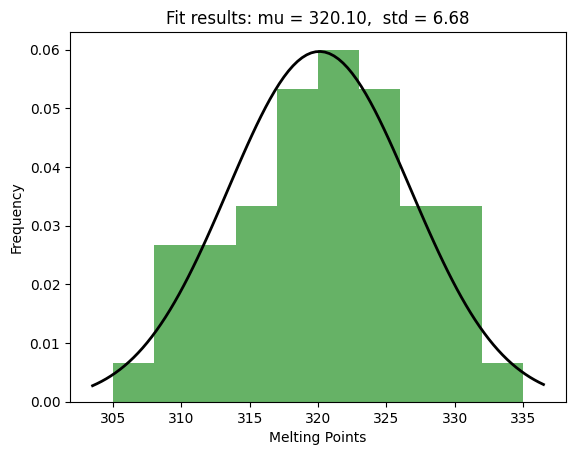

Statistics=0.989, p-value=0.919
Fail to reject the null hypothesis. The data appears to be normally distributed.


In [4]:
import numpy as np
from scipy.stats import shapiro
import matplotlib.pyplot as plt

# Given data
data = np.array([
    320, 326, 325, 318, 322, 320, 329, 317, 316, 331,
    320, 320, 317, 329, 316, 308, 321, 319, 322, 335,
    318, 313, 327, 314, 329, 323, 327, 323, 324, 314,
    308, 305, 328, 330, 322, 310, 324, 314, 312, 318,
    313, 320, 324, 311, 317, 325, 328, 319, 310, 324
])

# Divide the data into 10 categories (bins)
hist, bin_edges = np.histogram(data, bins=10)

# Plot the histogram
plt.hist(data, bins=bin_edges, density=True, alpha=0.6, color='g')

# Fit a normal distribution to the data
mu, sigma = np.mean(data), np.std(data)
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = np.exp(-(x - mu)**2 / (2 * sigma**2)) / (np.sqrt(2 * np.pi) * sigma)
plt.plot(x, p, 'k', linewidth=2)

# Title and labels
plt.title('Fit results: mu = %.2f,  std = %.2f' % (mu, sigma))
plt.xlabel('Melting Points')
plt.ylabel('Frequency')

# Show the plot
plt.show()

# Perform the Shapiro-Wilk test for normality
stat, p_value = shapiro(data)
print(f'Statistics={stat:.3f}, p-value={p_value:.3f}')

# Check the hypothesis at a significance level of 0.05
alpha = 0.05
if p_value > alpha:
    print("Fail to reject the null hypothesis. The data appears to be normally distributed.")
else:
    print("Reject the null hypothesis. The data does not appear to be normally distributed.")


In [5]:
#7
import pandas as pd
import numpy as np
from scipy.stats import norm, chi2

# Load the dataset
data = pd.read_csv("MSFT_stock_2020.csv")

# Calculate log-returns
log_returns = np.log(data["Close"].shift(-1) / data["Close"])

# Specify bin edges
bin_edges = [-np.inf, -0.001, -0.0004, 0, 0.0004, 0.001, np.inf]

# Compute observed frequencies
observed, _ = np.histogram(log_returns, bins=bin_edges)

# Chi-square goodness-of-fit test with specified normal parameters
mu, sigma = 0, 0.022
expected = len(log_returns) * np.diff(norm.cdf(bin_edges, mu, sigma))
chi_squared_stat = np.sum((observed - expected)**2 / expected)

# Degrees of freedom
df = len(bin_edges) - 1 - 2  # Two parameters estimated

# Critical value at alpha = 0.05
critical_value = chi2.ppf(1 - 0.05, df)

# Test the null hypothesis
reject_null_a = chi_squared_stat > critical_value

# Complete the table for (a)
categories = ['< -0.001', '[-0.001, -0.0004)', '[-0.0004, 0)', '[0, 0.0004)', '[0.0004, 0.001)', '>= 0.001']
table_a = pd.DataFrame({
    'Categories': categories,
    'Observed': observed,
    'Expected': expected
})

# Print results for (a)
print("Results for (a):")
print(table_a)
print(f"\nChi-square test statistic: {chi_squared_stat:.4f}")
print(f"Critical value at alpha=0.05 with {df} degrees of freedom: {critical_value:.4f}")
print(f"Do we reject the null hypothesis? {'Yes' if reject_null_a else 'No'}")

# Estimate parameters by MLE for (b)
mu_est, sigma_est = np.mean(log_returns), np.std(log_returns, ddof=1)

# Compute expected frequencies with estimated parameters
expected_est = len(log_returns) * np.diff(norm.cdf(bin_edges, mu_est, sigma_est))
chi_squared_stat_est = np.sum((observed - expected_est)**2 / expected_est)

# Degrees of freedom
df_est = len(bin_edges) - 1 - 2  # Two parameters estimated

# Critical value at alpha = 0.05
critical_value_est = chi2.ppf(1 - 0.05, df_est)

# Test the null hypothesis
reject_null_b = chi_squared_stat_est > critical_value_est

# Complete the table for (b)
table_b = pd.DataFrame({
    'Categories': categories,
    'Observed': observed,
    'Expected': expected_est  # Using estimated parameters
})

# Print results for (b)
print("\nResults for (b):")
print(table_b)
print(f"\nEstimated mu: {mu_est:.4f}, Estimated sigma: {sigma_est:.4f}")
print(f"Chi-square test statistic: {chi_squared_stat_est:.4f}")
print(f"Critical value at alpha=0.05 with {df_est} degrees of freedom: {critical_value_est:.4f}")
print(f"Do we reject the null hypothesis? {'Yes' if reject_null_b else 'No'}")


Results for (a):
          Categories  Observed     Expected
0           < -0.001      3949  4200.964476
1  [-0.001, -0.0004)       122    94.803029
2       [-0.0004, 0)        47    63.232494
3        [0, 0.0004)       277    63.232494
4    [0.0004, 0.001)       117    94.803029
5           >= 0.001      4205  4200.964476

Chi-square test statistic: 754.9576
Critical value at alpha=0.05 with 4 degrees of freedom: 9.4877
Do we reject the null hypothesis? Yes

Results for (b):
          Categories  Observed     Expected
0           < -0.001      3949  4055.878893
1  [-0.001, -0.0004)       122    96.248951
2       [-0.0004, 0)        47    64.258910
3        [0, 0.0004)       277    64.307686
4    [0.0004, 0.001)       117    96.504886
5           >= 0.001      4205  4340.800673

Estimated mu: 0.0009, Estimated sigma: 0.0216
Chi-square test statistic: 726.4047
Critical value at alpha=0.05 with 4 degrees of freedom: 9.4877
Do we reject the null hypothesis? Yes
